# Практическое занятие: базовые методы анализа сетевого трафика

---
## Структура ноутбука

1. **Блок 1. pcap → DataFrame.** Потоковое чтение, таблица пакетов, таблица потоков (5-tuple).
2. **Блок 2. Описательная статистика.** Распределения, CDF, QQ, тесты нормальности.
3. **Блок 3. Анализ сеансов.** Классификация TCP-потоков, сбойные диалоги.
4. **Блок 4. Fumbling.** Сканирование (по горизонтали и вертикали), ICMP-ошибки, DNS/HTTP-fumbling.
5. **Блок 5. Объём, время, биконинг.** Рабочий профиль, автокорреляция межинтервалов, локальность.
6. **Блок 6. Контент и граф связей.** DNS, HTTP, TLS SNI; идентификация приложений; NetworkX.

## 0. Подготовка окружения

Устанавливаем недостающие пакеты (если запуск ведётся впервые) и
фиксируем общие настройки отображения.

In [1]:
# При первом запуске выполните в терминале или отдельной ячейке:
# %pip install scapy pandas numpy matplotlib seaborn scipy networkx
# Wireshark не требуется: Scapy читает PCAP/PCAPNG самостоятельно.
import warnings, os, math, itertools, collections, ipaddress
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import networkx as nx
from scapy.all import *

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.titleweight"] = "bold"
np.random.seed(42)

# Укажите свой файл. None означает чтение всех пакетов во всех блоках.
# В этой версии исходного учебного кода таблица pkts целиком хранится в RAM.
PCAP_PATH = Path(r"Friday-WorkingHours.pcap")
PACKET_LIMIT = None
# Уточните эти диапазоны по схеме вашей сети перед выводом о локальности.
INTERNAL_CIDRS = ("10.0.0.0/8", "172.16.0.0/12", "192.168.0.0/16")
INTERNAL_NETS = tuple(ipaddress.ip_network(cidr) for cidr in INTERNAL_CIDRS)

def address_zone(value):
    if value is None or pd.isna(value):
        return "unknown"
    try:
        ip = ipaddress.ip_address(value)
    except ValueError:
        return "unknown"
    return "internal" if any(ip in net for net in INTERNAL_NETS) else "external"

assert PCAP_PATH.is_file(), f"PCAP не найден: {PCAP_PATH}"
print("Файл готов:", PCAP_PATH, f"{PCAP_PATH.stat().st_size/1e6:.1f} МБ")
print("Лимит пакетов:", PACKET_LIMIT if PACKET_LIMIT is not None else "весь файл")
if PACKET_LIMIT is None and PCAP_PATH.stat().st_size > 1_000_000_000:
    print("Внимание: исходный DataFrame и операции по нему могут потребовать много ОЗУ; "
          "первый блок будет работать долго. Это ограничение исходного подхода pandas.")

Файл готов: Friday-WorkingHours.pcap 8839.3 МБ
Лимит пакетов: весь файл
Внимание: исходный DataFrame и операции по нему могут потребовать много ОЗУ; первый блок будет работать долго. Это ограничение исходного подхода pandas.


---
# Блок 1. pcap → DataFrame: подготовка данных

> **Collins, гл. 1, 3.** «Quality source data is integral to good security analysis».
> Сетевой трафик - это компромисс выразительности и объёма:
> pcap содержит всё, но поиск по нему дорог.

## Что здесь делаем

1. **Потоковое чтение.** `scapy.PcapReader` разбирает пакеты по одному и не грузит дамп целиком в память. Для учебного дампа ~25 МБ это избыточно, но привычка полезная: на реальной «боевой» задаче дампы измеряются гигабайтами.
2. **Таблица пакетов.** Один пакет - одна строка. Табличное представление позволяет извлечь наиболее важную информацию из пакетов и далее обрабатывать их, используя все возможности pandas
3. **Таблица потоков.** Агрегация по 5-tuple (src, sport, dst, dport, proto).



In [2]:
%%time
def parse_pcap(path, limit=None):
    rows = []
    with PcapReader(str(path)) as rdr:
        for i, pkt in enumerate(rdr):
            if limit is not None and i >= limit:
                break
            row = {
                "ts": float(pkt.time), "length": len(pkt),
                "src_mac": pkt[Ether].src if pkt.haslayer(Ether) else None,
                "dst_mac": pkt[Ether].dst if pkt.haslayer(Ether) else None,
                "src_ip": None, "dst_ip": None, "ip_ver": None, "l4": None,
                "src_port": None, "dst_port": None, "tcp_flags": None,
                "icmp_type": None, "icmp_code": None,
                "ip_id": None, "ip_ttl": None, "ip_len": None, "tcp_seq": None,
            }
            if pkt.haslayer(IP):
                ip = pkt[IP]
                row.update(src_ip=ip.src, dst_ip=ip.dst, ip_ver=4,
                           ip_id=int(ip.id), ip_ttl=int(ip.ttl), ip_len=int(ip.len))
            elif pkt.haslayer(IPv6):
                ip = pkt[IPv6]
                row.update(src_ip=ip.src, dst_ip=ip.dst, ip_ver=6)
            if pkt.haslayer(TCP):
                t = pkt[TCP]
                row.update(l4="TCP", src_port=int(t.sport), dst_port=int(t.dport),
                           tcp_flags=str(t.flags), tcp_seq=int(t.seq))
            elif pkt.haslayer(UDP):
                u = pkt[UDP]
                row.update(l4="UDP", src_port=int(u.sport), dst_port=int(u.dport))
            elif pkt.haslayer(ICMP):
                ic = pkt[ICMP]
                row.update(l4="ICMP", icmp_type=int(ic.type), icmp_code=int(ic.code))
            rows.append(row)
            if (i + 1) % 250_000 == 0:
                print(f"Прочитано {i+1:,} пакетов...", flush=True)
    df = pd.DataFrame(rows)
    if df.empty:
        raise ValueError("В выбранной части файла нет пакетов")
    df["dt"] = pd.to_datetime(df["ts"], unit="s", utc=True)
    df["src_zone"] = df["src_ip"].map(address_zone)
    df["dst_zone"] = df["dst_ip"].map(address_zone)
    return df

pkts = parse_pcap(PCAP_PATH, limit=PACKET_LIMIT)
print(f"Прочитано пакетов: {len(pkts):,}")
print("Направления по зонам (в выбранных пакетах):")
display(pkts.groupby(["src_zone", "dst_zone"]).size().rename("packets"))
print("Зоны получены по INTERNAL_CIDRS; private-адрес за пределами вашей сети может потребовать уточнения списка.")

Прочитано 250,000 пакетов...
Прочитано 500,000 пакетов...
Прочитано 750,000 пакетов...
Прочитано 1,000,000 пакетов...
Прочитано 1,250,000 пакетов...
Прочитано 1,500,000 пакетов...
Прочитано 1,750,000 пакетов...
Прочитано 2,000,000 пакетов...
Прочитано 2,250,000 пакетов...
Прочитано 2,500,000 пакетов...
Прочитано 2,750,000 пакетов...
Прочитано 3,000,000 пакетов...
Прочитано 3,250,000 пакетов...
Прочитано 3,500,000 пакетов...
Прочитано 3,750,000 пакетов...
Прочитано 4,000,000 пакетов...
Прочитано 4,250,000 пакетов...
Прочитано 4,500,000 пакетов...
Прочитано 4,750,000 пакетов...
Прочитано 5,000,000 пакетов...
Прочитано 5,250,000 пакетов...
Прочитано 5,500,000 пакетов...
Прочитано 5,750,000 пакетов...
Прочитано 6,000,000 пакетов...
Прочитано 6,250,000 пакетов...
Прочитано 6,500,000 пакетов...
Прочитано 6,750,000 пакетов...
Прочитано 7,000,000 пакетов...
Прочитано 7,250,000 пакетов...
Прочитано 7,500,000 пакетов...
Прочитано 7,750,000 пакетов...
Прочитано 8,000,000 пакетов...
Прочитано 8,25

src_zone  dst_zone
external  external      28507
          internal    4065673
internal  external    3323991
          internal    2526016
unknown   unknown       53687
Name: packets, dtype: int64

Зоны получены по INTERNAL_CIDRS; private-адрес за пределами вашей сети может потребовать уточнения списка.
CPU times: total: 38min 28s
Wall time: 39min 27s


In [3]:
pkts.head()

,ts,length,src_mac,dst_mac,src_ip,dst_ip,ip_ver,l4,src_port,dst_port,tcp_flags,icmp_type,icmp_code,ip_id,ip_ttl,ip_len,tcp_seq,dt,src_zone,dst_zone
0,1.499429e+09,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-07-07 11:59:39.599128008+00:00,unknown,unknown
1,1.499429e+09,458,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-07-07 11:59:43.018330097+00:00,unknown,unknown
2,1.499429e+09,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-07-07 11:59:45.798480034+00:00,unknown,unknown
3,1.499429e+09,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-07-07 11:59:46.231251001+00:00,unknown,unknown
4,1.499429e+09,458,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-07-07 11:59:48.398910999+00:00,unknown,unknown


### Таблица потоков по 5-tuple

Поток это совокупность пакетов с одинаковыми 5-tuple (имеет смысл только для l4 трафика TCP или UDP).

In [4]:
# Ключ объединяет оба направления 5-tuple, не назначая роли сторон.
# Число порта само по себе не определяет, кто начал разговор.
def canon_key(s):
    a = (str(s["src_ip"]), int(s["src_port"]))
    b = (str(s["dst_ip"]), int(s["dst_port"]))
    first, second = sorted((a, b))
    s["flow_key"] = (*first, *second, s["l4"])
    return s

In [5]:
#выделяем только интересующие протоколы (TCP, UDP, ICMP)
mask = pkts["src_ip"].notna() & pkts["dst_ip"].notna() & pkts["l4"].isin(["TCP","UDP","ICMP"])
p = pkts[mask].copy()

In [6]:
# Порядок индекса DataFrame сохраняет порядок пакетов в файле.
p["src_port"] = p["src_port"].fillna(-1).astype(int)
p["dst_port"] = p["dst_port"].fillna(-1).astype(int)
p["flow_key"] = None
p["direction"] = "unknown"

In [7]:
%%time
p = p.apply(canon_key, axis=1)

# Первый SYN без ACK задаёт инициатора TCP, даже если SYN+ACK встречается раньше.
# Если SYN не попал в запись, направление TCP остаётся неизвестным.
syn = (p["l4"].eq("TCP") & p["tcp_flags"].fillna("").map(
    lambda flags: "S" in flags and "A" not in flags))
origin_rows = pd.concat([
    p.loc[syn].drop_duplicates("flow_key", keep="first"),
    p.loc[p["l4"].ne("TCP")].drop_duplicates("flow_key", keep="first"),
])
origin = {row.flow_key: (row.src_ip, int(row.src_port))
          for row in origin_rows.itertuples(index=False)}
p["initiator_ip"] = p["flow_key"].map(lambda key: origin.get(key, (None, None))[0])
p["initiator_port"] = p["flow_key"].map(lambda key: origin.get(key, (None, None))[1])
known = p["initiator_ip"].notna()
forward = known & p["src_ip"].eq(p["initiator_ip"]) & p["src_port"].eq(p["initiator_port"])
p.loc[forward, "direction"] = "forward"
p.loc[known & ~forward, "direction"] = "reverse"
print(f"TCP без наблюдаемого SYN: {p.loc[p.l4.eq('TCP') & ~known, 'flow_key'].nunique():,} разговоров; их инициатор неизвестен.")

TCP без наблюдаемого SYN: 4 разговоров; их инициатор неизвестен.
CPU times: total: 37min 47s
Wall time: 47min 40s


In [8]:
%%time
flows = p.groupby("flow_key").agg(
        start = ("ts", "min"),
        end   = ("ts", "max"),
        pkts  = ("ts", "size"),
        bytes_total = ("length", "sum"),
        pkts_fwd = ("direction", lambda x: (x=="forward").sum()),
        pkts_rev = ("direction", lambda x: (x=="reverse").sum()),
        bytes_fwd = ("length",   lambda x: x[p.loc[x.index,"direction"]=="forward"].sum()),
        bytes_rev = ("length",   lambda x: x[p.loc[x.index,"direction"]=="reverse"].sum()),
        tcp_flags_set = ("tcp_flags", lambda x: set([f for f in x.dropna()])),
    ).reset_index()

unknown_tcp = flows.loc[flows["flow_key"].map(lambda k: k[-1] == "TCP") &
                        flows["pkts_fwd"].eq(0) & flows["pkts_rev"].eq(0)]
print(f"Разговоров: {len(flows):,}; TCP с неизвестным инициатором: {len(unknown_tcp):,}.")
print("pkts_fwd/rev и bytes_fwd/rev считаются относительно инициатора; у TCP без SYN оба направления остаются неизвестными.")

Разговоров: 397,040; TCP с неизвестным инициатором: 4.
pkts_fwd/rev и bytes_fwd/rev считаются относительно инициатора; у TCP без SYN оба направления остаются неизвестными.
CPU times: total: 6min 25s
Wall time: 6min 34s


In [9]:
flows

,flow_key,start,end,pkts,bytes_total,pkts_fwd,pkts_rev,bytes_fwd,bytes_rev,tcp_flags_set
0,"(1.1.70.73, 80, 192.168.10.15, 52756, TCP)",1.499435e+09,1.499435e+09,10,4791,5,5,564,4227,"{SA, PA, FA, A, S, FPA}"
1,"(1.1.70.73, 80, 192.168.10.15, 52760, TCP)",1.499435e+09,1.499435e+09,9,1805,5,4,566,1239,"{SA, FA, PA, A, S}"
2,"(1.1.70.73, 80, 192.168.10.15, 52761, TCP)",1.499435e+09,1.499435e+09,9,1695,5,4,566,1129,"{SA, FA, PA, A, S}"
3,"(1.1.70.73, 80, 192.168.10.15, 52762, TCP)",1.499435e+09,1.499435e+09,9,1644,5,4,566,1078,"{SA, FA, PA, A, S}"
4,"(1.1.70.73, 80, 192.168.10.15, 52763, TCP)",1.499435e+09,1.499435e+09,9,1835,5,4,566,1269,"{SA, FA, PA, A, S}"
...,...,...,...,...,...,...,...,...,...,...
397035,"(fe80::f470:cd16:3cf6:bd7b, 56740, ff02::1:3, ...",1.499446e+09,1.499446e+09,13,1378,13,0,1378,0,{}
397036,"(fe80::f470:cd16:3cf6:bd7b, 56983, ff02::1:3, ...",1.499432e+09,1.499432e+09,26,3952,26,0,3952,0,{}
397037,"(fe80::f470:cd16:3cf6:bd7b, 61206, ff02::1:3, ...",1.499446e+09,1.499446e+09,26,3952,26,0,3952,0,{}
397038,"(fe80::f470:cd16:3cf6:bd7b, 62800, ff02::1:3, ...",1.499433e+09,1.499433e+09,26,2782,26,0,2782,0,{}


In [10]:
# src/dst здесь означают инициатора/ответчика, а не порядок портов.
# Неопределённые TCP-разговоры сохраняются в flows, но роли им не назначаем.
def oriented_endpoints(key):
    a = (key[0], key[1]); b = (key[2], key[3])
    initiator = origin.get(key)
    if initiator is None:
        return (None, None, None, None, key[4])
    responder = b if initiator == a else a
    return (*initiator, *responder, key[4])

flows[["src_ip", "src_port", "dst_ip", "dst_port", "l4"]] = pd.DataFrame(
    flows["flow_key"].map(oriented_endpoints).tolist(), index=flows.index)
flows["duration"] = flows["end"] - flows["start"]
flows["src_zone"] = flows["src_ip"].map(address_zone)
flows["dst_zone"] = flows["dst_ip"].map(address_zone)
print("Зоны инициаторов и ответчиков:")
display(flows.groupby(["src_zone", "dst_zone"]).size().rename("flows"))
print("unknown/unknown в TCP означает отсутствие наблюдаемого начального SYN; такие потоки не включаются в выводы по инициатору.")

Зоны инициаторов и ответчиков:


src_zone  dst_zone
external  external        88
          internal        10
internal  external     86118
          internal    310820
unknown   unknown          4
Name: flows, dtype: int64

unknown/unknown в TCP означает отсутствие наблюдаемого начального SYN; такие потоки не включаются в выводы по инициатору.


In [11]:
flows.sort_values("pkts", ascending=False).head(5)

,flow_key,start,end,pkts,bytes_total,pkts_fwd,pkts_rev,bytes_fwd,bytes_rev,tcp_flags_set,src_ip,src_port,dst_ip,dst_port,l4,duration,src_zone,dst_zone
7721,"(13.107.4.50, 80, 192.168.10.15, 49808, TCP)",1.499430e+09,1.499430e+09,2466364,3208485890,1046329,1420035,63863479,3144622411,"{RA, SA, PA, A, S}",192.168.10.15,49808.0,13.107.4.50,80.0,TCP,710.301351,internal,external
279636,"(192.168.10.15, 50273, 8.253.104.126, 80, TCP)",1.499431e+09,1.499431e+09,413351,650464031,180264,233087,10837845,639626186,"{SA, FA, PA, A, S}",192.168.10.15,50273.0,8.253.104.126,80.0,TCP,213.674427,internal,external
278986,"(192.168.10.15, 49765, 23.15.4.9, 80, TCP)",1.499430e+09,1.499430e+09,46709,55164801,24441,22268,1551372,53613429,"{SA, PA, FA, A, S, FPA}",192.168.10.15,49765.0,23.15.4.9,80.0,TCP,5.488452,internal,external
307758,"(192.168.10.16, 53564, 91.189.88.162, 80, TCP)",1.499429e+09,1.499429e+09,42775,56887726,16975,25800,1127111,55760615,"{SA, FA, PA, A, S}",192.168.10.16,53564.0,91.189.88.162,80.0,TCP,12.056839,internal,external
256481,"(192.168.10.12, 48292, 91.189.88.161, 80, TCP)",1.499429e+09,1.499429e+09,39743,54088478,16253,23490,1077955,53010523,"{SA, FA, PA, A, S}",192.168.10.12,48292.0,91.189.88.161,80.0,TCP,11.848239,internal,external


In [12]:
#сколько потоков состоят всего из одного пакета
(flows["pkts"] == 1).sum()

print(f"Однопакетных разговоров: {(flows['pkts'] == 1).sum():,} из {len(flows):,}. "
      "Это может быть запрос без ответа или неполный захват; само по себе не доказывает сбой.")

Однопакетных разговоров: 399 из 397,040. Это может быть запрос без ответа или неполный захват; само по себе не доказывает сбой.


In [13]:
#распределение потоков по протоколам (по количеству и переданным байтам)
by_l4_flows = flows["l4"].value_counts(normalize=True).rename("share_flows")
by_l4_bytes = flows.groupby("l4")["bytes_total"].sum()
by_l4_bytes = (by_l4_bytes / by_l4_bytes.sum()).rename("share_bytes")
pd.concat([by_l4_flows, by_l4_bytes], axis=1)

print("share_flows — доля разговоров; share_bytes — доля объёма. Лидеры по этим двум показателям могут различаться.")

share_flows — доля разговоров; share_bytes — доля объёма. Лидеры по этим двум показателям могут различаться.


### Исследование конечных узлов дампа и предположений о топологии сети

In [14]:
pkts

,ts,length,src_mac,dst_mac,src_ip,dst_ip,ip_ver,l4,src_port,dst_port,tcp_flags,icmp_type,icmp_code,ip_id,ip_ttl,ip_len,tcp_seq,dt,src_zone,dst_zone
0,1.499429e+09,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-07-07 11:59:39.599128008+00:00,unknown,unknown
1,1.499429e+09,458,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-07-07 11:59:43.018330097+00:00,unknown,unknown
2,1.499429e+09,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-07-07 11:59:45.798480034+00:00,unknown,unknown
3,1.499429e+09,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-07-07 11:59:46.231251001+00:00,unknown,unknown
4,1.499429e+09,458,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017-07-07 11:59:48.398910999+00:00,unknown,unknown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9997869,1.499458e+09,60,00:c1:b1:14:eb:31,b8:ac:6f:36:07:ee,23.10.108.151,192.168.10.14,4.0,TCP,443.0,59111.0,A,NaN,NaN,56145.0,54.0,40.0,1.094031e+09,2017-07-07 20:02:41.005390882+00:00,external,internal
9997870,1.499458e+09,74,00:c1:b1:14:eb:31,b8:ac:6f:36:0b:a8,162.213.33.50,192.168.10.51,4.0,TCP,443.0,59581.0,SA,NaN,NaN,0.0,49.0,60.0,2.636445e+09,2017-07-07 20:02:41.073163986+00:00,external,internal
9997871,1.499458e+09,66,b8:ac:6f:36:0b:a8,00:c1:b1:14:eb:31,192.168.10.51,162.213.33.50,4.0,TCP,59581.0,443.0,A,NaN,NaN,54971.0,64.0,52.0,1.682897e+09,2017-07-07 20:02:41.073210955+00:00,internal,external
9997872,1.499458e+09,214,b8:ac:6f:36:0b:a8,00:c1:b1:14:eb:31,192.168.10.51,162.213.33.50,4.0,TCP,59581.0,443.0,PA,NaN,NaN,54972.0,64.0,200.0,1.682897e+09,2017-07-07 20:02:41.073622942+00:00,internal,external


In [15]:
melted_pkts = pkts[['src_ip','dst_ip']].melt()

In [16]:
melted_pkts

,variable,value
0,src_ip,NaN
1,src_ip,NaN
2,src_ip,NaN
3,src_ip,NaN
4,src_ip,NaN
...,...,...
19995743,dst_ip,192.168.10.14
19995744,dst_ip,192.168.10.51
19995745,dst_ip,162.213.33.50
19995746,dst_ip,162.213.33.50


In [17]:
# Количество уникальных IP и MAC, отдельно по семействам адресов.
ip_count = pd.unique(pkts[["src_ip", "dst_ip"]].to_numpy().ravel())
mac_count = pd.unique(pkts[["src_mac", "dst_mac"]].to_numpy().ravel())
print("Уникальных IP:", sum(pd.notna(v) for v in ip_count))
print("Уникальных MAC:", sum(pd.notna(v) for v in mac_count))
print("Один MAC в кадрах с несколькими IP может быть шлюзом на стороне точки захвата, но это не привязка этих IP к его сетевой карте.")

Уникальных IP: 8353
Уникальных MAC: 34
Один MAC в кадрах с несколькими IP может быть шлюзом на стороне точки захвата, но это не привязка этих IP к его сетевой карте.


In [18]:
#выборка всех l3 пакетов (у которых есть IP адрес)
pkts_l3 = pkts[pkts['src_ip'].notna()]

In [19]:
# Эти ребра означают наблюдаемое L2 соседство, не владение IP адресом.
# При пересылке через роутер dst_mac может быть его интерфейсом, а dst_ip — удалённым узлом.
source_links = pkts_l3[["src_ip", "src_mac"]].rename(
    columns={"src_ip": "IP", "src_mac": "MAC"}).assign(observed_as="source")
destination_links = pkts_l3[["dst_ip", "dst_mac"]].rename(
    columns={"dst_ip": "IP", "dst_mac": "MAC"}).assign(observed_as="destination")
ip_mac = pd.concat([source_links, destination_links], ignore_index=True).dropna()
ip_mac["IP"] = "IP " + ip_mac["IP"].astype(str)
ip_mac["MAC"] = "MAC " + ip_mac["MAC"].astype(str)

In [20]:
ip_mac

,IP,MAC,observed_as
0,IP 192.168.10.50,MAC 00:19:b9:0a:69:f1,source
1,IP 192.168.10.50,MAC 00:19:b9:0a:69:f1,source
2,IP 192.168.10.3,MAC 18:66:da:9b:e3:7d,source
3,IP 192.168.10.3,MAC 18:66:da:9b:e3:7d,source
4,IP 192.168.10.50,MAC 00:19:b9:0a:69:f1,source
...,...,...,...
19888369,IP 192.168.10.14,MAC b8:ac:6f:36:07:ee,destination
19888370,IP 192.168.10.51,MAC b8:ac:6f:36:0b:a8,destination
19888371,IP 162.213.33.50,MAC 00:c1:b1:14:eb:31,destination
19888372,IP 162.213.33.50,MAC 00:c1:b1:14:eb:31,destination


In [21]:
# Сохраняем граф из оригинала, но читаем его ребра как L2-наблюдения.
G = nx.from_pandas_edgelist(ip_mac, source="IP", target="MAC")
print(f"Граф L2-соседства: {G.number_of_nodes():,} вершин, {G.number_of_edges():,} рёбер.")

Граф L2-соседства: 8,386 вершин, 8,359 рёбер.


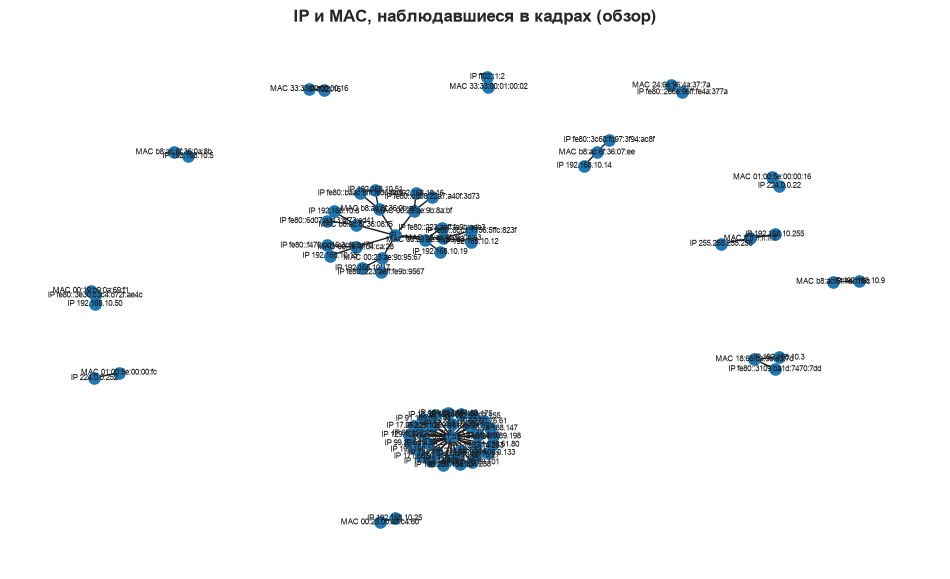

Ребро на графе означает соседство в наблюдавшемся кадре, а не постоянное соответствие IP и MAC.


In [22]:
# Полный граф на большой выборке нечитаем; рисуем только 20 MAC с
# наибольшим числом соседей и не более 30 соседних IP для каждого.
mac_rank = sorted((node for node in G if node.startswith("MAC ")),
                  key=lambda node: G.degree(node), reverse=True)[:20]
visible = set(mac_rank)
for mac in mac_rank:
    visible.update(list(G.neighbors(mac))[:30])
L2_visible = G.subgraph(visible)
if L2_visible.number_of_nodes():
    fig, ax = plt.subplots(figsize=(12, 7))
    nx.draw(L2_visible, nx.spring_layout(L2_visible, seed=42), ax=ax,
            node_size=65, font_size=6, with_labels=True)
    ax.set_title("IP и MAC, наблюдавшиеся в кадрах (обзор)")
    plt.show()
print("Ребро на графе означает соседство в наблюдавшемся кадре, а не постоянное соответствие IP и MAC.")

In [23]:
# Степень MAC — предварительный признак. Для перехода между сегментами
# ищем две копии одного IPv4-пакета с TTL уменьшенным на 1 и иными L2 MAC.
routers = [node for node in G if node.startswith("MAC ") and G.degree(node) > 1]
print(f"MAC с несколькими соседними IP: {len(routers):,} (кандидаты, не доказанные маршрутизаторы).")
same_packet = ["src_ip", "dst_ip", "ip_id", "ip_len", "l4",
               "src_port", "dst_port", "tcp_seq"]
ipv4_frames = pkts_l3.dropna(subset=["ip_id", "ip_ttl", "src_mac", "dst_mac"])
crossings = []
for _, group in ipv4_frames.groupby(same_packet, dropna=False, sort=False):
    if len(group) < 2:
        continue
    group = group.sort_values("ts", kind="stable")
    for earlier, later in zip(group.iloc[:-1].itertuples(), group.iloc[1:].itertuples()):
        if (0 <= later.ts - earlier.ts <= 2 and earlier.ip_ttl == later.ip_ttl + 1
            and earlier.dst_mac != later.dst_mac
            and earlier.src_mac != later.src_mac):
            crossings.append((earlier.dst_mac, later.src_mac, earlier.src_ip,
                              earlier.dst_ip, earlier.ts, later.ts))
router_transitions = pd.DataFrame(crossings,
    columns=["ingress_mac", "egress_mac", "src_ip", "dst_ip", "seen_in", "seen_out"])
router_interfaces = (router_transitions.groupby(["ingress_mac", "egress_mac"])
                     .size().rename("packets").sort_values(ascending=False))
print("Пары MAC с признаком транзита IPv4 через разные L2-сегменты:")
display(router_interfaces.head(20))
print("TTL−1 и смена L2-адресов поддерживают гипотезу транзита; повторение IP ID и неполная точка захвата могут дать ложное совпадение.")

MAC с несколькими соседними IP: 12 (кандидаты, не доказанные маршрутизаторы).
Пары MAC с признаком транзита IPv4 через разные L2-сегменты:


Series([], Name: packets, dtype: int64)

TTL−1 и смена L2-адресов поддерживают гипотезу транзита; повторение IP ID и неполная точка захвата могут дать ложное совпадение.


In [24]:
print("MAC-кандидаты по числу соседних IP (топ-20):")
display(pd.Series({mac: G.degree(mac) for mac in routers},
                  name="observed_ip_neighbors").sort_values(ascending=False).head(20))
print("В разных сегментах интерфейсы одного маршрутизатора имеют разные MAC; не объединяйте их без признаков транзита.")

MAC-кандидаты по числу соседних IP (топ-20):


MAC 00:c1:b1:14:eb:31    8309
MAC b8:ac:6f:36:08:f5       3
MAC b8:ac:6f:36:0b:a8       3
MAC 00:23:ae:9b:95:67       3
MAC b8:ac:6f:36:04:e3       3
MAC 00:1e:4f:d4:ca:28       3
MAC 00:23:ae:9b:ad:b3       3
MAC 00:23:ae:9b:8a:bf       3
MAC b8:ac:6f:36:07:ee       2
MAC 18:66:da:9b:e3:7d       2
MAC 00:19:b9:0a:69:f1       2
MAC ff:ff:ff:ff:ff:ff       2
Name: observed_ip_neighbors, dtype: int64

В разных сегментах интерфейсы одного маршрутизатора имеют разные MAC; не объединяйте их без признаков транзита.


In [25]:
print("Соседи самого связанного MAC (если есть):")
print(list(G.neighbors(routers[0]))[:20] if routers else "Кандидатов нет")

Соседи самого связанного MAC (если есть):
['IP 192.168.10.50', 'IP fe80::3e30:c3c4:d72f:ae4c']


In [26]:
print("Соседи второго MAC-кандидата (если есть):")
print(list(G.neighbors(routers[1]))[:20] if len(routers) > 1 else "Второго кандидата нет")

Соседи второго MAC-кандидата (если есть):
['IP 192.168.10.3', 'IP fe80::3109:ba1d:7470:7dd']


---
# Блок 2. Описательная статистика и распределения


In [27]:
length = pkts["length"]
iat_all = pkts["ts"].diff().dropna()
iat_all = iat_all[iat_all > 0]  # отбросим нулевые — одновременные пакеты

summary = pd.DataFrame({
    "packet_length": length.describe(),
    "interarrival_sec": iat_all.describe(),
})
summary

print(f"Медианная длина пакета: {length.median():.0f} байт; "
      f"медианный положительный интервал: {iat_all.median():.6g} с"
      if len(iat_all) else "Положительных межпакетных интервалов нет.")
print("Длинный хвост длины или интервалов оценивайте вместе с ECDF ниже; время зависит от позиции датчика и порядка пакетов.")

Медианная длина пакета: 74 байт; медианный положительный интервал: 9.5129e-05 с
Длинный хвост длины или интервалов оценивайте вместе с ECDF ниже; время зависит от позиции датчика и порядка пакетов.


## Анализ длин пакетов
Для анализа метаданных пакетов используются два основных представления: гистограмма и график ECDF (Empirical Cumulative Distribution Function) - эмпирическая накопленная функция распределения
Гистограммы (столбчатые диаграммы распределения) очень зависят от того, на сколько бинов вы разделили данные.
Если бинов слишком мало — теряются детали.
Если слишком много — появляется шум.
ECDF не имеет параметров, она показывает все данные как есть, без агрегации.

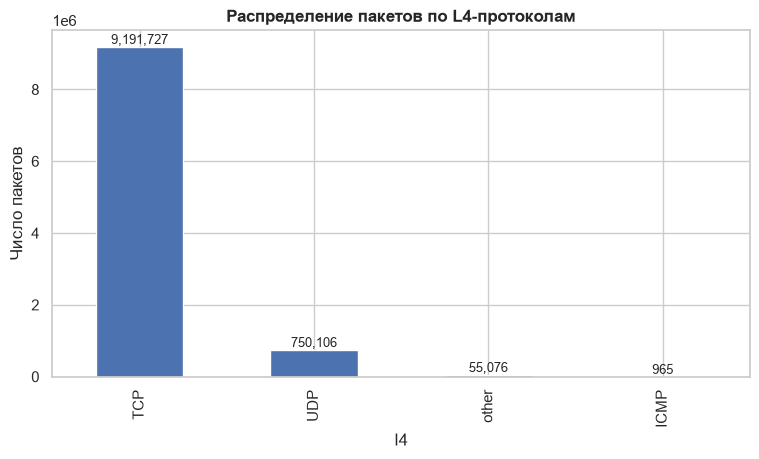

Больше всего пакетов относится к TCP: 9,191,727 из 9,997,874. Это структура наблюдаемого дампа, а не признак атаки.


In [28]:
# Bar chart распределения по протоколам
proto_counts = pkts["l4"].fillna("other").value_counts()
ax = proto_counts.plot.bar(color="#4C72B0")
ax.set_title("Распределение пакетов по L4-протоколам")
ax.set_ylabel("Число пакетов")
for i, v in enumerate(proto_counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.show()

print(f"Больше всего пакетов относится к {proto_counts.index[0]}: {proto_counts.iloc[0]:,} из {len(pkts):,}. Это структура наблюдаемого дампа, а не признак атаки.")

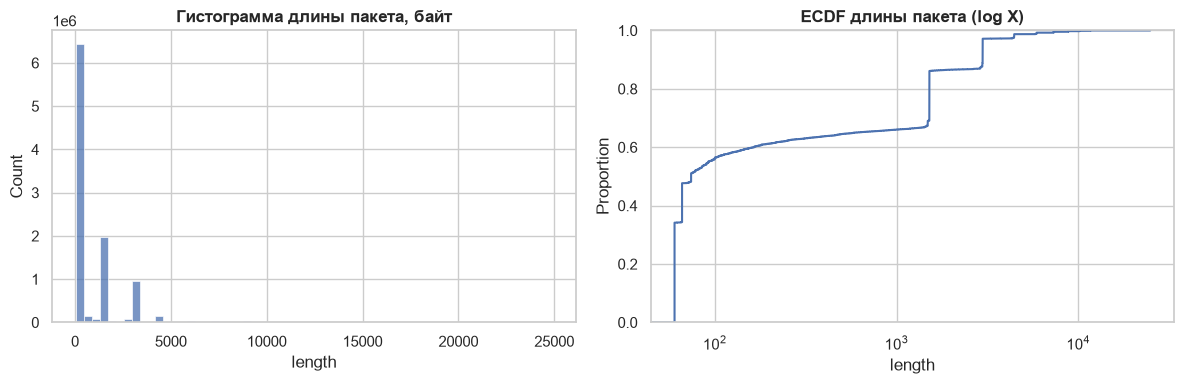

Гистограмма показывает частоты размеров, ECDF — долю пакетов не длиннее заданного размера; на логарифмической оси виден хвост.


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(length, bins=60, ax=axes[0], kde=False)
axes[0].set_title("Гистограмма длины пакета, байт")
sns.ecdfplot(length, ax=axes[1])
axes[1].set_xscale("log"); axes[1].set_title("ECDF длины пакета (log X)")
plt.tight_layout(); plt.show()

print("Гистограмма показывает частоты размеров, ECDF — долю пакетов не длиннее заданного размера; на логарифмической оси виден хвост.")

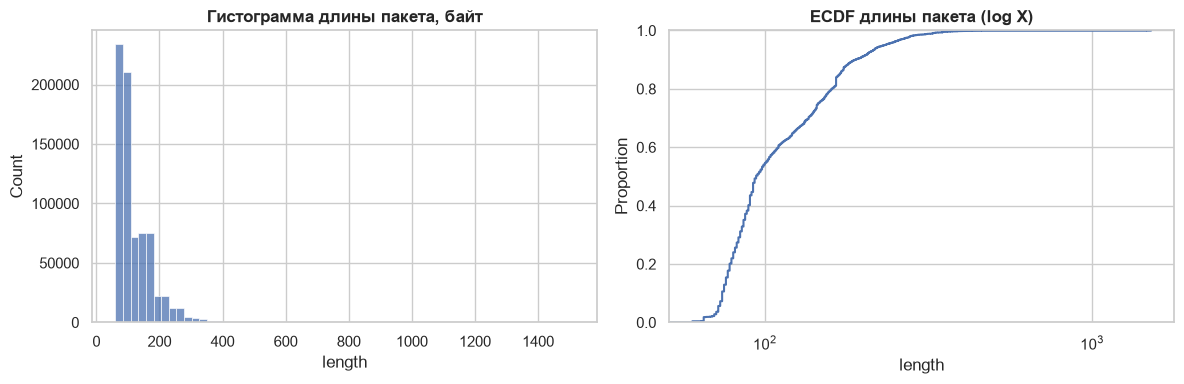

UDP: 750,106 пакетов; медиана длины — 94 байт.


In [65]:
protocol_length = pkts[pkts['l4'] == 'UDP']['length']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(protocol_length, bins=60, ax=axes[0], kde=False)
axes[0].set_title("Гистограмма длины пакета, байт")
sns.ecdfplot(protocol_length, ax=axes[1])
axes[1].set_xscale("log"); axes[1].set_title("ECDF длины пакета (log X)")
plt.tight_layout(); plt.show()

print(f"UDP: {len(protocol_length):,} пакетов; медиана длины — "
      f"{protocol_length.median():.0f} байт." if len(protocol_length)
      else "UDP: пакетов нет; распределение не интерпретируется.")

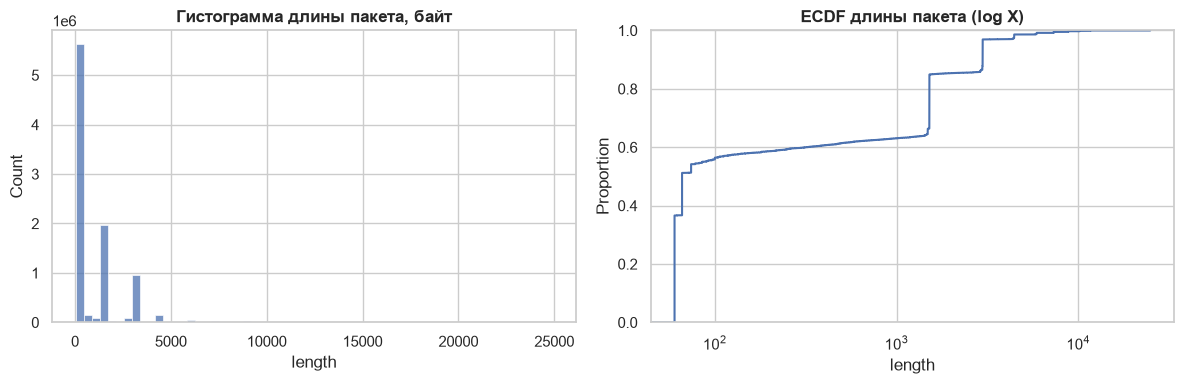

TCP: 9,191,727 пакетов; медиана длины — 66 байт.


In [66]:
protocol_length = pkts[pkts['l4'] == 'TCP']['length']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(protocol_length, bins=60, ax=axes[0], kde=False)
axes[0].set_title("Гистограмма длины пакета, байт")
sns.ecdfplot(protocol_length, ax=axes[1])
axes[1].set_xscale("log"); axes[1].set_title("ECDF длины пакета (log X)")
plt.tight_layout(); plt.show()

print(f"TCP: {len(protocol_length):,} пакетов; медиана длины — "
      f"{protocol_length.median():.0f} байт." if len(protocol_length)
      else "TCP: пакетов нет; распределение не интерпретируется.")

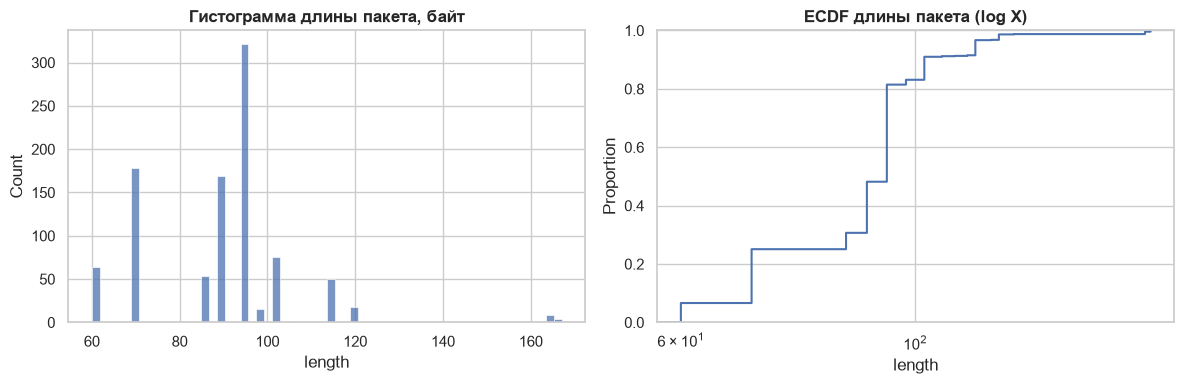

ICMP: 965 пакетов; медиана длины — 94 байт.


In [67]:
protocol_length = pkts[pkts['l4'] == 'ICMP']['length']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(protocol_length, bins=60, ax=axes[0], kde=False)
axes[0].set_title("Гистограмма длины пакета, байт")
sns.ecdfplot(protocol_length, ax=axes[1])
axes[1].set_xscale("log"); axes[1].set_title("ECDF длины пакета (log X)")
plt.tight_layout(); plt.show()

print(f"ICMP: {len(protocol_length):,} пакетов; медиана длины — "
      f"{protocol_length.median():.0f} байт." if len(protocol_length)
      else "ICMP: пакетов нет; распределение не интерпретируется.")

## Анализ межпакетных интервалов

При анализе межпакетных интервалов возникает проблема "длинного хвоста", значения, которые наблюдаются чаще всего "ломают" масштаб и делают невозможным анализ более редких значений. По этой причине традиционно применяется двойная логарифмическая шкала

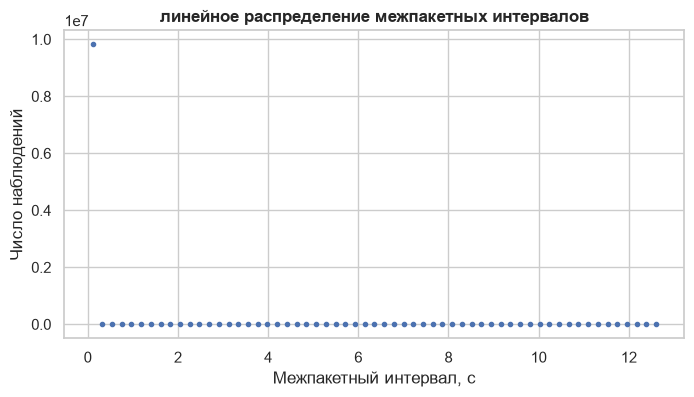

Линейный график показывает концентрацию коротких интервалов; редкие длинные интервалы могут сжимать масштаб.


In [33]:
fig, ax = plt.subplots(figsize=(8, 4))
hist, edges = np.histogram(iat_all, bins=np.linspace(iat_all.min(),
                                                     iat_all.max(), 60))
centers = (edges[:-1]+edges[1:]) / 2
ax.scatter(centers, hist , marker=".", linestyle="None")
ax.set_xlabel("Межпакетный интервал, с")
ax.set_ylabel("Число наблюдений")
ax.set_title("линейное распределение межпакетных интервалов")
plt.show()

print("Линейный график показывает концентрацию коротких интервалов; редкие длинные интервалы могут сжимать масштаб.")

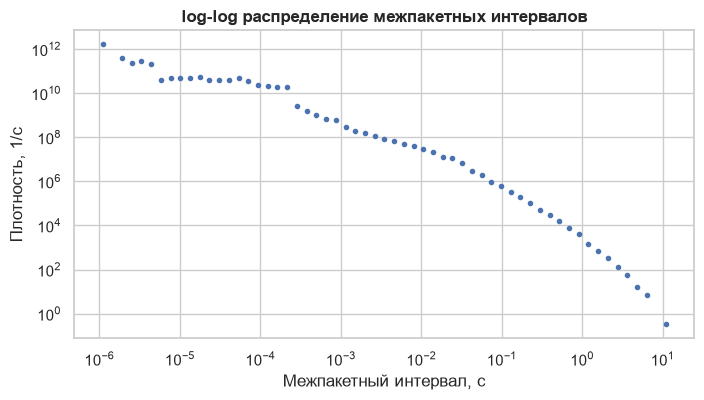

Log-log показывает хвост интервалов; форму кривой нельзя отождествлять с конкретным приложением без контекста.


In [34]:
# log-log гистограмма межпакетного интервала — тяжёлые хвосты видны визуально
fig, ax = plt.subplots(figsize=(8, 4))

iat_pos = iat_all[iat_all > 0]
edges = np.logspace(np.log10(iat_pos.min()),
                    np.log10(iat_pos.max()), 60)
hist, _ = np.histogram(iat_pos, bins=edges)
widths = np.diff(edges)
centers = np.sqrt(edges[:-1] * edges[1:])
density = hist / widths

mask = hist > 0
ax.loglog(centers[mask], density[mask], marker=".", linestyle="None")

ax.set_xlabel("Межпакетный интервал, с")
ax.set_ylabel("Плотность, 1/с")
ax.set_title("log-log распределение межпакетных интервалов")
#ax.grid(True, which='both', linestyle='--', alpha=0.4)
plt.show()

print("Log-log показывает хвост интервалов; форму кривой нельзя отождествлять с конкретным приложением без контекста.")

---
# Блок 3. Анализ сеансов

> Состояние TCP-потока
> определяется наблюдаемой последовательностью флагов. Нас интересуют пять
> классов:
>
> - **full** — наблюдалось полное "тройное рукопожатие" (SYN, SYN+ACK, ACK);
> - **syn_only** — только SYN от инициатора, ответа нет;
> - **syn_synack_no_ack** — есть SYN-ACK, но инициатор не завершил рукопожатие;
> - **rst_terminated** — встречался RST;
> - **fin_closed** — корректное завершение с FIN;
> - **unknown/other** — остальные комбинации.

## Почему это важно

SYN без ответа и масса half-open соединений — классический признак сканирования (или примитивной DDoS атаки).

In [35]:
def classify_tcp(flag_set):
    s = set(flag_set) if flag_set else set()
    has_syn     = any("S" in f and "A" not in f for f in s)   # S без A
    has_synack  = any("S" in f and "A" in f for f in s)       # SA
    has_ack_only= any(f == "A" for f in s)
    has_rst     = any("R" in f for f in s)
    has_fin     = any("F" in f for f in s)
    if has_rst:                                   return "rst_terminated"
    if has_syn and has_synack and has_ack_only:   return "full"
    if has_syn and has_synack and not has_ack_only: return "syn_synack_no_ack"
    if has_syn and not has_synack:                return "syn_only"
    if has_fin and has_synack:                    return "fin_closed"
    return "other"

class
rst_terminated       228506
full                  64932
syn_only                563
syn_synack_no_ack       128
other                     2
Name: count, dtype: int64


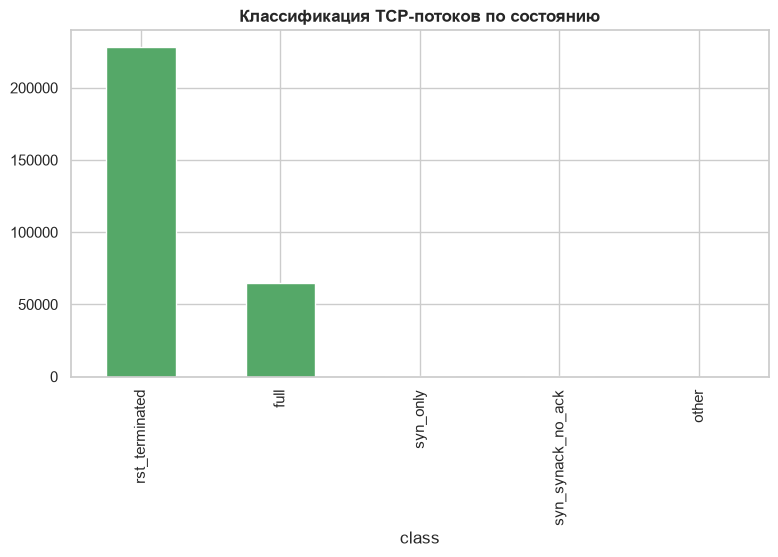

Лидирующий наблюдаемый класс: rst_terminated (228,506 из 294,131).
Классы основаны на флагах, замеченных в захвате; потерянные пакеты могут менять класс.


In [37]:
tcp = flows[flows["l4"] == "TCP"].copy()
tcp["class"] = tcp["tcp_flags_set"].apply(classify_tcp)
tcp_class_counts = tcp["class"].value_counts()
print(tcp_class_counts)
ax = tcp_class_counts.plot.bar(color="#55A868")
ax.set_title("Классификация TCP-потоков по состоянию")
plt.show()

print(f"Лидирующий наблюдаемый класс: {tcp_class_counts.index[0]} "
      f"({tcp_class_counts.iloc[0]:,} из {len(tcp):,})." if len(tcp_class_counts)
      else "TCP-потоков нет; классификация не строится.")
print("Классы основаны на флагах, замеченных в захвате; потерянные пакеты могут менять класс.")

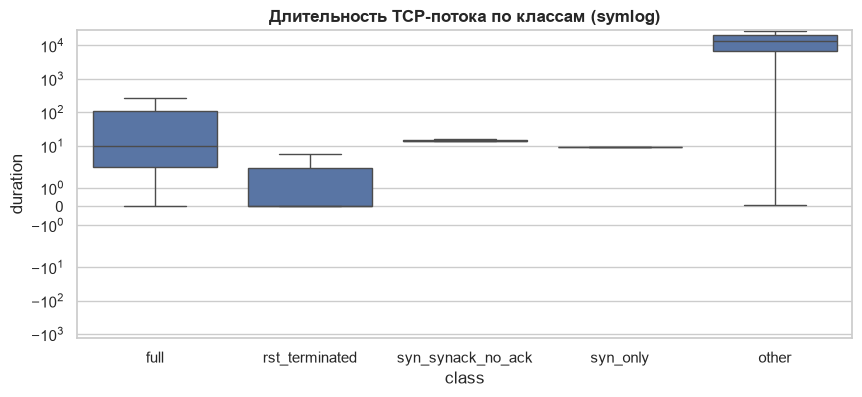


10 самых длинных TCP-сессий:


,src_ip,src_port,dst_ip,dst_port,pkts,bytes_total,duration,class
378987,NaN,NaN,NaN,NaN,51,7234,26760.499117,other
306158,192.168.10.16,48318.0,192.168.10.50,139.0,290,26850,18302.569177,full
252784,192.168.10.12,39524.0,192.168.10.50,139.0,290,26842,18002.607704,full
89177,172.16.0.1,40490.0,192.168.10.50,80.0,29,16774,16010.880878,rst_terminated
89183,172.16.0.1,40492.0,192.168.10.50,80.0,19,12789,16010.705313,rst_terminated
89191,172.16.0.1,40494.0,192.168.10.50,80.0,17,12681,16002.204152,rst_terminated
89215,172.16.0.1,40500.0,192.168.10.50,80.0,30,26617,15648.517253,rst_terminated
89223,172.16.0.1,40502.0,192.168.10.50,80.0,19,12801,15648.483185,rst_terminated
89232,172.16.0.1,40504.0,192.168.10.50,80.0,36,23845,15642.600318,rst_terminated
383639,192.168.10.5,53899.0,205.174.165.73,8080.0,15,1238,13954.616793,rst_terminated



10 самых коротких (duration>0) TCP-сессий:


,src_ip,src_port,dst_ip,dst_port,pkts,bytes_total,duration,class
221984,172.16.0.1,64915.0,192.168.10.50,12345.0,2,120,9.536743e-07,rst_terminated
213469,172.16.0.1,62784.0,192.168.10.50,3077.0,2,120,9.536743e-07,rst_terminated
57868,172.16.0.1,35780.0,192.168.10.50,3268.0,2,134,9.536743e-07,rst_terminated
119349,172.16.0.1,45002.0,192.168.10.50,5877.0,2,120,9.536743e-07,rst_terminated
138943,172.16.0.1,49025.0,192.168.10.50,8087.0,2,120,9.536743e-07,rst_terminated
162453,172.16.0.1,53446.0,192.168.10.50,1186.0,2,120,9.536743e-07,rst_terminated
110709,172.16.0.1,43924.0,192.168.10.50,26.0,2,120,9.536743e-07,rst_terminated
88284,172.16.0.1,40272.0,192.168.10.50,2968.0,2,134,9.536743e-07,rst_terminated
138710,172.16.0.1,49025.0,192.168.10.50,3737.0,2,120,9.536743e-07,rst_terminated
130624,172.16.0.1,47412.0,192.168.10.50,4444.0,2,134,9.536743e-07,rst_terminated


Длинные разговоры могут включать простои; высокая асимметрия означает перекос переданных байтов, а не автоматически утечку.


In [38]:
# Асимметрия по байтам и длительности
tcp["asym"] = (tcp["bytes_fwd"] - tcp["bytes_rev"]).abs() / tcp["bytes_total"].replace(0, np.nan)
tcp["duration"] = tcp["end"] - tcp["start"]

fig, ax = plt.subplots(figsize=(10,4))
sns.boxplot(data=tcp[tcp["pkts"] >= 2], x="class", y="duration", ax=ax, showfliers=False)
ax.set_yscale("symlog")
ax.set_title("Длительность TCP-потока по классам (symlog)")
plt.show()

print("\n10 самых длинных TCP-сессий:")
display_cols = ["src_ip","src_port","dst_ip","dst_port","pkts","bytes_total","duration","class"]
display(tcp.sort_values("duration", ascending=False).head(10)[display_cols])

print("\n10 самых коротких (duration>0) TCP-сессий:")
display(tcp[tcp["duration"]>0].sort_values("duration").head(10)[display_cols])

print("Длинные разговоры могут включать простои; высокая асимметрия означает перекос переданных байтов, а не автоматически утечку.")

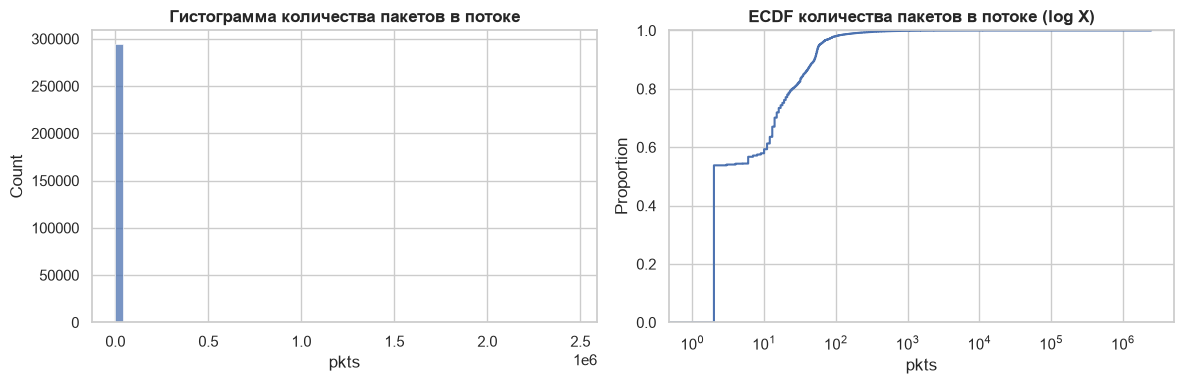

ECDF теперь относится к количеству пакетов в TCP-разговоре, как и подпись оси; ранее использовалась оставшаяся переменная длины ICMP.


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(tcp['pkts'], bins=60, ax=axes[0], kde=False)
axes[0].set_title("Гистограмма количества пакетов в потоке")
sns.ecdfplot(tcp["pkts"], ax=axes[1])
axes[1].set_xscale("log"); axes[1].set_title("ECDF количества пакетов в потоке (log X)")
plt.tight_layout(); plt.show()

print("ECDF теперь относится к количеству пакетов в TCP-разговоре, как и подпись оси; ранее использовалась оставшаяся переменная длины ICMP.")

In [40]:
tcp.sort_values("asym", ascending=False)

print("Высокая асимметрия требует проверки абсолютного объёма: у малого потока она почти всегда близка к 1.")

Высокая асимметрия требует проверки абсолютного объёма: у малого потока она почти всегда близка к 1.


---
# Блок 4. Fumbling: обнаружение сканирования и ошибок конфигурации

> Атакующие перебирают разные варианты воздействия и порождают ошибки
> в сети или аномальные активности. Выделяем:
>
> - **горизонтальный скан** — один порт, много адресов;
> - **вертикальный скан** — один адрес, много портов;
> - **ICMP-ошибки** (Destination/Port Unreachable, Time Exceeded);
> - **DNS fumbling** — NXDOMAIN, длинные/энтропийные имена (DGA-кандидаты);
> - **HTTP fumbling** — массовые 4xx/5xx.

## Вычисления

Для каждого источника считаем *спред*: число уникальных адресов и портов
назначения, и долю потоков без ответа (classes `syn_only`, `syn_synack_no_ack`).

In [41]:
# Спред источника и доля неуспешных TCP-попыток
tcp_with_src = tcp.copy()
#неуспешные попытки - незавершенные рукопожатия + завершение сеанса по RST
tcp_with_src["failed"] = tcp_with_src["class"].isin(["syn_only","syn_synack_no_ack","rst_terminated"])

src_stats = tcp_with_src[tcp_with_src["src_ip"].notna()].groupby("src_ip").agg(
    flows = ("dst_ip","size"),
    uniq_dst_ip  = ("dst_ip","nunique"),
    uniq_dst_port= ("dst_port","nunique"),
    failed_rate  = ("failed","mean"),
).sort_values(["failed_rate","uniq_dst_ip"], ascending=False)

src_stats["src_zone"] = src_stats.index.map(address_zone)
print("Спред рассчитан только для TCP с установленным инициатором; зона src_zone помогает отдельно оценивать внутренние и внешние источники.")
if len(src_stats):
    print("Инициаторы по зонам:")
    display(src_stats.groupby("src_zone").agg(sources=("flows", "size"),
                                             flows=("flows", "sum")))

Спред рассчитан только для TCP с установленным инициатором; зона src_zone помогает отдельно оценивать внутренние и внешние источники.
Инициаторы по зонам:


,sources,flows
src_zone,,
internal,14,294127


In [42]:
top_spread = src_stats[src_stats["flows"] >= 5]
top_spread

print(f"Источник с >=5 TCP-разговорами: {len(top_spread):,}. Сравнивайте спред вместе с числом попыток.")

Источник с >=5 TCP-разговорами: 14. Сравнивайте спред вместе с числом попыток.


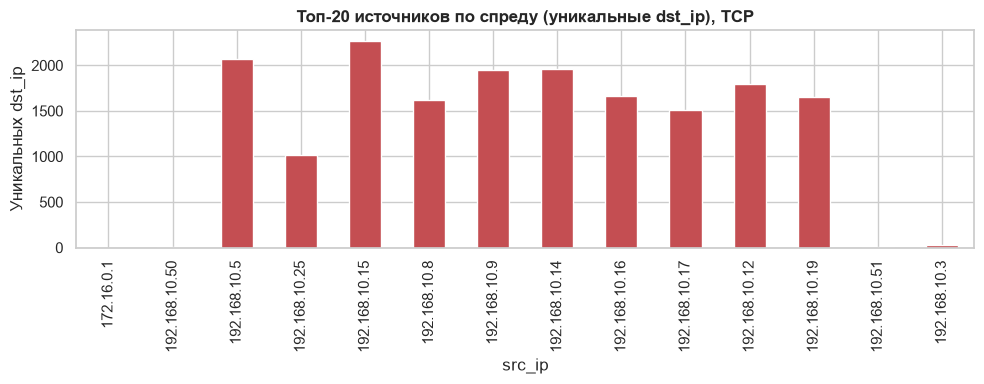

Большое число разных адресатов делает источник кандидатом для проверки; направление и зона источника приведены в src_stats.


In [43]:
fig, ax = plt.subplots(figsize=(10,4))
top_spread["uniq_dst_ip"].plot.bar(ax=ax, color="#C44E52")
ax.set_title("Топ-20 источников по спреду (уникальные dst_ip), TCP")
ax.set_ylabel("Уникальных dst_ip")
plt.tight_layout(); plt.show()

print("Большое число разных адресатов делает источник кандидатом для проверки; направление и зона источника приведены в src_stats.")

In [44]:
# Горизонтальный vs вертикальный скан для каждого источника
# horizontal_ratio = uniq_dst_ip / flows; vertical_ratio = uniq_dst_port / flows
src_stats["horiz_ratio"] = src_stats["uniq_dst_ip"] / src_stats["flows"]
src_stats["vert_ratio"]  = src_stats["uniq_dst_port"]/ src_stats["flows"]

cand = src_stats[(src_stats["flows"] >= 10) & (src_stats["failed_rate"] > 0.5)]
print("Кандидаты на сканирование (failed_rate > 50%, >=10 потоков):")
display(cand.sort_values("horiz_ratio", ascending=False).head(15))

print(f"Кандидатов по заданным порогам: {len(cand):,}. "
      "Высокие отношения адресатов/портов и доля незавершений — повод исследовать временное окно, а не вывод о сканировании.")

Кандидаты на сканирование (failed_rate > 50%, >=10 потоков):


,flows,uniq_dst_ip,uniq_dst_port,failed_rate,src_zone,horiz_ratio,vert_ratio
src_ip,,,,,,,
192.168.10.50,199,5,4,0.964824,internal,0.025126,0.020101
172.16.0.1,204884,1,999,0.999414,internal,0.000005,0.004876


Кандидатов по заданным порогам: 2. Высокие отношения адресатов/портов и доля незавершений — повод исследовать временное окно, а не вывод о сканировании.


In [45]:
# ICMP-ошибки как индикатор fumbling
icmp = pkts[pkts["l4"] == "ICMP"].copy()
if len(icmp):
    icmp_summary = icmp.groupby(["icmp_type","icmp_code"]).size().reset_index(name="count")
    display(icmp_summary.sort_values("count", ascending=False).head(15))

    top_sources_icmp = icmp.groupby("src_ip").size().sort_values(ascending=False).head(10)
    print("\nИсточники ICMP-ошибок (топ-10):")
    display(top_sources_icmp)
else:
    print("ICMP в дампе отсутствует.")

if len(icmp):
    print("ICMP type/code показывают реакции сети; echo type 0/8 исключайте из числа ошибок при интерпретации.")

,icmp_type,icmp_code,count
1,3.0,1.0,453
2,3.0,3.0,352
0,0.0,0.0,65
5,8.0,0.0,65
4,3.0,10.0,29
3,3.0,4.0,1



Источники ICMP-ошибок (топ-10):


src_ip
172.16.0.1        488
192.168.10.50     340
192.168.10.51      26
192.168.10.1       21
210.14.132.70      12
77.238.121.220     11
109.201.130.57     11
172.16.0.2         10
109.201.130.58      9
192.168.10.14       8
dtype: int64

ICMP type/code показывают реакции сети; echo type 0/8 исключайте из числа ошибок при интерпретации.


In [46]:
# DNS fumbling: извлекаем запросы/ответы и смотрим NXDOMAIN, длину/энтропию имени
letterFrequency = {
    'E': 12.0, 'T': 9.10, 'A': 8.12, 'O': 7.68, 'I': 7.31, 'N': 6.95,
    'S': 6.28, 'R': 6.02, 'H': 5.92, 'D': 4.32, 'L': 3.98, 'U': 2.88,
    'C': 2.71, 'M': 2.61, 'F': 2.30, 'Y': 2.11, 'W': 2.09, 'G': 2.03,
    'P': 1.82, 'B': 1.49, 'V': 1.11, 'K': 0.69, 'X': 0.17, 'Q': 0.11,
    'J': 0.10, 'Z': 0.07,
}

# Нормируем проценты в вероятности и приводим ключи к нижнему регистру.
_TOTAL = sum(letterFrequency.values())
_REF_P = {k.lower(): v / _TOTAL for k, v in letterFrequency.items()}

# Малая вероятность для символов вне таблицы (цифры, дефис, точка, не-ASCII):
# без сглаживания -log2(0) сломает расчёт на первом же таком символе.
_SMOOTH = 1e-4

def shannon_entropy(s):
    """Кросс-энтропия строки под эталонным английским распределением букв,
    бит/символ.

    Для 'example.com' значение получится порядка 4 бит/символ,
    для DGA-подобного 'xkzqwvpj' — около 9+ бит/символ.
    Чем выше, тем меньше строка похожа на нормальный английский текст."""
    if not s:
        return 0.0
    chars = [c for c in s.lower() if c.isalpha()]
    if not chars:
        return 0.0
    return -sum(math.log2(_REF_P.get(c, _SMOOTH)) for c in chars) / len(chars)
    


In [47]:
%%time
dns_rows = []
with PcapReader(str(PCAP_PATH)) as rdr:
    for pkt in itertools.islice(rdr, PACKET_LIMIT):
        if pkt.haslayer(DNS):
            d = pkt[DNS]
            qname = ""
            try:
                if d.qd is not None:
                    qname = d.qd.qname.decode(errors="ignore").rstrip(".")
            except Exception:
                pass
            dns_rows.append({
                "ts": float(pkt.time),
                "qr": int(d.qr),          # 0=query, 1=response
                "rcode": int(d.rcode),    # 3 = NXDOMAIN
                "qname": qname,
                "qname_len": len(qname),
                "qname_entropy": shannon_entropy(qname),
            })
dns = pd.DataFrame(dns_rows, columns=["ts", "qr", "rcode", "qname", "qname_len", "qname_entropy"])
print(f"DNS-сообщений: {len(dns):,}")
if len(dns):
    responses = dns[dns["qr"] == 1]
    if len(responses):
        nx_rate = (responses["rcode"] == 3).mean()
        print(f"Доля NXDOMAIN: {nx_rate:.1%}")
    dns["qname"].value_counts().head(10).to_frame("count")

if len(dns):
    print("NXDOMAIN — доля среди DNS-ответов в выбранных пакетах; опечатки и автопоиск имён тоже дают NXDOMAIN.")

DNS-сообщений: 676,073
Доля NXDOMAIN: 1.1%
NXDOMAIN — доля среди DNS-ответов в выбранных пакетах; опечатки и автопоиск имён тоже дают NXDOMAIN.
CPU times: total: 29min 52s
Wall time: 30min 51s


In [ ]:
dns.sort_values("qname_entropy", ascending=False) if len(dns) else print("DNS не наблюдался")

print("Высокая энтропия имени — признак для проверки с частотой и источником запросов; сама по себе не означает туннель.")

---
# Блок 5. Объём, время, биконинг

> Временнóй анализ строится на трёх идеях:
>
> - **рабочий профиль** — сутки обычно имеют плато и провал; всплески в
>   «нерабочее» время подозрительны;
> - **биконинг** — канал управления (C2) периодичен, у него низкий CV
>   межинтервалов и пик автокорреляции на периоде T;
> - **локальность** — нормальный пользователь общается с небольшим
>   «рабочим множеством» хостов; резкий рост — признак raid/эксфильтрации.

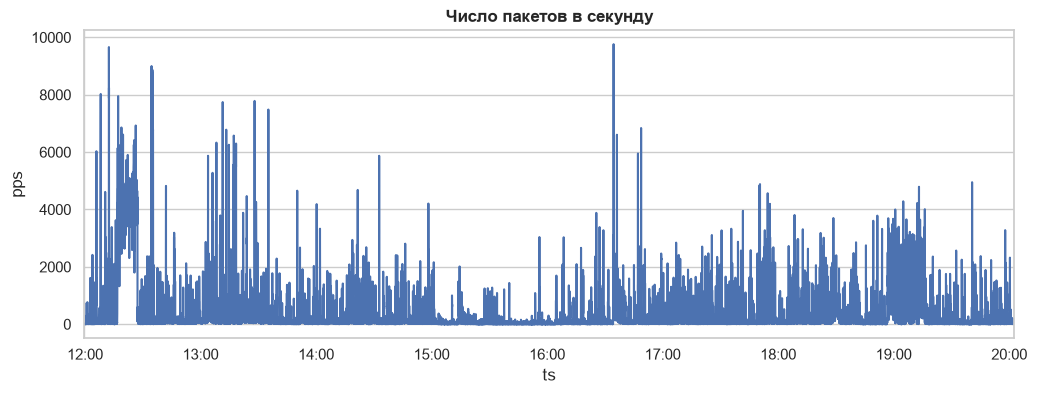

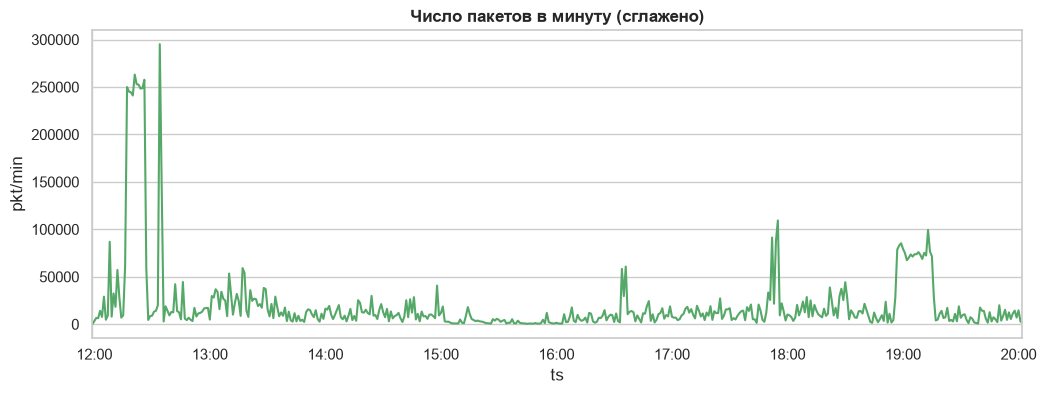

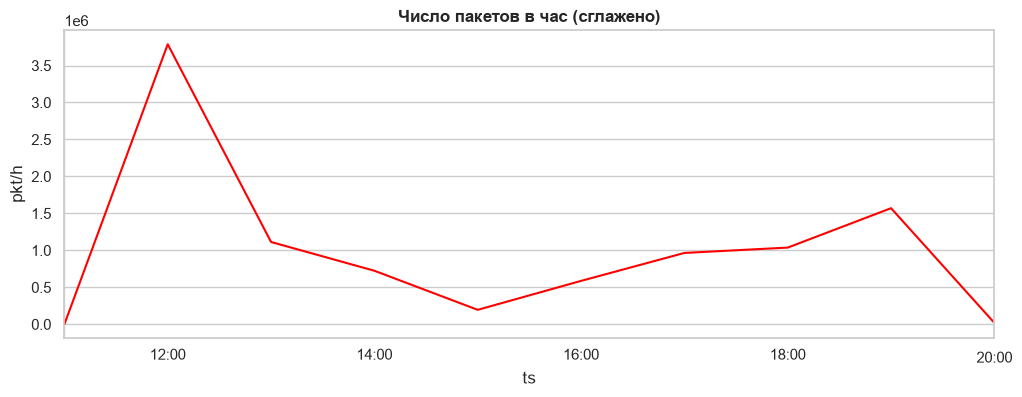

Пик минутной нагрузки: 295,125 пакетов в 2017-07-07 12:34:00+00:00 (UTC). Сверяйте пик с расписанием и ролями адресов.
Графики секунды/минуты/часы показывают разный масштаб; подписанное время — UTC, выборка ограничена PACKET_LIMIT.


In [48]:
ts_series = pd.Series(1, index=pd.to_datetime(pkts["ts"], unit="s", utc=True))
by_sec = ts_series.resample("1s").sum()

fig, ax = plt.subplots(figsize=(12, 4))
by_sec.plot(ax=ax, color="#4C72B0")
ax.set_title("Число пакетов в секунду")
ax.set_ylabel("pps")
plt.show()

by_min = ts_series.resample("1min").sum()
fig, ax = plt.subplots(figsize=(12, 4))
by_min.plot(ax=ax, color="#55A868")
ax.set_title("Число пакетов в минуту (сглажено)")
ax.set_ylabel("pkt/min")
plt.show()

by_hour = ts_series.resample("1h").sum()
fig, ax = plt.subplots(figsize=(12, 4))
by_hour.plot(ax=ax, color="red")
ax.set_title("Число пакетов в час (сглажено)")
ax.set_ylabel("pkt/h")
plt.show()

if len(by_min):
    peak_time, peak_n = by_min.idxmax(), int(by_min.max())
    print(f"Пик минутной нагрузки: {peak_n:,} пакетов в {peak_time} (UTC). Сверяйте пик с расписанием и ролями адресов.")
print("Графики секунды/минуты/часы показывают разный масштаб; подписанное время — UTC, выборка ограничена PACKET_LIMIT.")

In [49]:
# Локальность: окно уникальных dst_ip по каждому src_ip
p = pkts.dropna(subset=["src_ip","dst_ip"]).copy()
p["dt"] = pd.to_datetime(p["ts"], unit="s", utc=True)




In [50]:
flows.groupby('src_ip')['dst_ip'].nunique().sort_values(ascending=False)

print("Большое число адресатов у одного инициатора нужно сопоставить с зоной, портами и долей неуспешных попыток.")

Большое число адресатов у одного инициатора нужно сопоставить с зоной, портами и долей неуспешных попыток.


In [51]:
# Выбираем из наблюдаемого трафика, а не фиксированный IP чужого дампа.
observed_sources = flows[flows["src_ip"].notna()].groupby("src_ip")["dst_ip"].nunique()
top_src = observed_sources.idxmax() if len(observed_sources) else None
print("Источник для графика локальности:", top_src,
      "| зона:", address_zone(top_src))

Источник для графика локальности: 192.168.10.15 | зона: internal


In [52]:
sub = (p[p["src_ip"] == top_src].set_index("dt").sort_index()
       if top_src is not None else p.iloc[:0].set_index("dt"))

In [53]:
# Количество уникальных dst_ip в  окне 5 минут
uniq_rolling = (sub["dst_ip"].resample("5min").nunique())

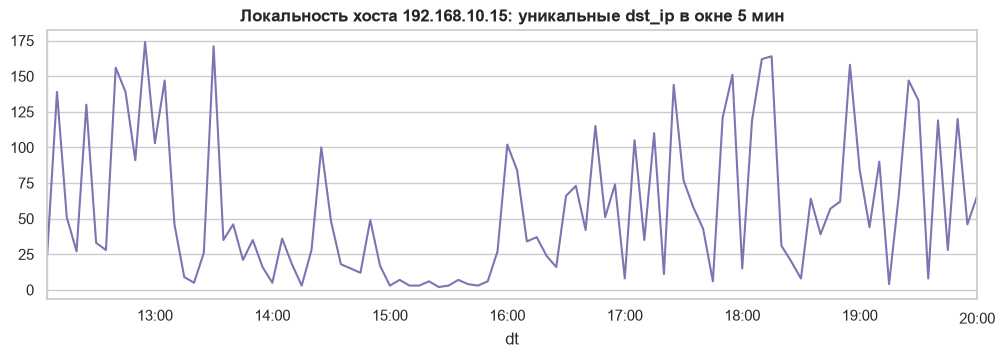

Локальность — число уникальных получателей за 5 минут. Рост проверяйте вместе с портами и зоной источника.


In [54]:
fig, ax = plt.subplots(figsize=(12,3.5))
uniq_rolling.plot(ax=ax, color="#8172B2")
ax.set_title(f"Локальность хоста {top_src}: уникальные dst_ip в окне 5 мин")
plt.show()

print("Локальность — число уникальных получателей за 5 минут. Рост проверяйте вместе с портами и зоной источника.")

---
# Блок 6. Контент-анализ, идентификация приложений, граф коммуникаций

> Текст в трафике (DNS, HTTP, TLS SNI) —
> источник быстрых и надёжных выводов о приложении. Граф коммуникаций
> (NetworkX) показывает «центральные» узлы — хабы, серверы, маршрутизаторы.

## План блока

1. HTTP: Host, URI, User-Agent, коды ответа (сканируем Raw-слой на ASCII-заголовки).
2. TLS SNI: вытащить из ClientHello, без расшифровки.
3. Идентификация приложения: порт vs баннер vs поведение — сравнение.
4. Граф: NetworkX.DiGraph по потокам, центральности degree/betweenness/closeness.

SNI читается из полей ClientHello без загрузки модуля TLS Scapy; если ClientHello разбит между TCP-сегментами, имя не будет извлечено.


In [55]:
# Простой извлекатель HTTP-заголовков из Raw-слоя
import re
RE_HTTP_REQ  = re.compile(rb"^(?P<method>GET|POST|PUT|DELETE|HEAD|OPTIONS|PATCH)\s+(?P<uri>\S+)\s+HTTP/1\.[01]", re.M)
RE_HTTP_HDR  = re.compile(rb"^(?P<name>[A-Za-z\-]+):\s*(?P<val>[^\r\n]+)", re.M)
RE_HTTP_RESP = re.compile(rb"^HTTP/1\.[01]\s+(?P<code>\d{3})", re.M)

In [56]:
# Продолжаем читать тот же PCAP_PATH, что и в блоке 1.
http_rows = []
with PcapReader(str(PCAP_PATH)) as rdr:
    for pkt in itertools.islice(rdr, PACKET_LIMIT):
        if pkt.haslayer(Raw) and pkt.haslayer(TCP):
            raw = bytes(pkt[Raw].load)[:2000]
            if b"HTTP/1." not in raw:
                continue
            row = {"ts": float(pkt.time),
                   "src_ip": pkt[IP].src if pkt.haslayer(IP) else None,
                   "dst_ip": pkt[IP].dst if pkt.haslayer(IP) else None,
                   "dst_port": int(pkt[TCP].dport),
                   "method": None, "uri": None, "host": None,
                   "user_agent": None, "code": None}
            m = RE_HTTP_REQ.search(raw)
            if m:
                row["method"] = m.group("method").decode()
                row["uri"]    = m.group("uri").decode(errors="ignore")
            m = RE_HTTP_RESP.search(raw)
            if m:
                row["code"] = int(m.group("code"))
            for hm in RE_HTTP_HDR.finditer(raw):
                name = hm.group("name").decode().lower()
                val  = hm.group("val").decode(errors="ignore")
                if name == "host":        row["host"] = val
                elif name == "user-agent":row["user_agent"] = val
            http_rows.append(row)

http = pd.DataFrame(http_rows, columns=["ts", "src_ip", "dst_ip", "dst_port", "method", "uri", "host", "user_agent", "code"])
print(f"HTTP-наблюдений: {len(http):,}")

print("HTTP извлекается из незашифрованного Raw TCP; отсутствие записей не означает отсутствие веб-трафика (HTTPS не виден как HTTP).")

HTTP-наблюдений: 301,911
HTTP извлекается из незашифрованного Raw TCP; отсутствие записей не означает отсутствие веб-трафика (HTTPS не виден как HTTP).


In [57]:
http['code'].value_counts()

print("HTTP 4xx/5xx следует сверять с Host, URI и временем; отдельный код не доказывает ошибку конфигурации.")

HTTP 4xx/5xx следует сверять с Host, URI и временем; отдельный код не доказывает ошибку конфигурации.


In [58]:
http['method'].value_counts()

print("Частоты методов HTTP показывают наблюдаемую активность, не количество разных пользователей.")

Частоты методов HTTP показывают наблюдаемую активность, не количество разных пользователей.


In [59]:
# SNI из TLS ClientHello в байтах TCP-пакета. TLS-модуль Scapy не нужен.
# Поддерживаются целые TLS record и ClientHello внутри одного TCP-пакета.
def extract_sni(pkt):
    if not pkt.haslayer(TCP):
        return None
    data = bytes(pkt[TCP].payload)
    if len(data) < 9 or data[0] != 22 or data[1] != 3:
        return None
    record_len = int.from_bytes(data[3:5], "big")
    if len(data) < 5 + record_len:
        return None  # часть TLS record осталась в другом TCP-сегменте
    record = data[5:5+record_len]
    if len(record) < 4 or record[0] != 1:  # handshake type 1 = ClientHello
        return None
    hello_len = int.from_bytes(record[1:4], "big")
    if len(record) < 4 + hello_len:
        return None
    hello = record[4:4+hello_len]
    if len(hello) < 35:
        return None
    pos = 34  # версия TLS (2) + random (32)
    session_len = hello[pos]
    pos += 1 + session_len
    if pos + 2 > len(hello):
        return None
    cipher_len = int.from_bytes(hello[pos:pos+2], "big")
    pos += 2 + cipher_len
    if pos + 1 > len(hello):
        return None
    compression_len = hello[pos]
    pos += 1 + compression_len
    if pos + 2 > len(hello):
        return None
    extensions_len = int.from_bytes(hello[pos:pos+2], "big")
    pos += 2
    end = pos + extensions_len
    if end > len(hello):
        return None
    while pos + 4 <= end:
        kind = int.from_bytes(hello[pos:pos+2], "big")
        size = int.from_bytes(hello[pos+2:pos+4], "big")
        pos += 4
        if pos + size > end:
            return None
        extension = hello[pos:pos+size]
        pos += size
        if kind != 0 or len(extension) < 5:  # 0 = server_name
            continue
        names_len = int.from_bytes(extension[:2], "big")
        if names_len + 2 > len(extension):
            return None
        at = 2
        while at + 3 <= names_len + 2:
            name_type = extension[at]
            name_len = int.from_bytes(extension[at+1:at+3], "big")
            at += 3
            if at + name_len > names_len + 2:
                return None
            if name_type == 0:
                try:
                    return extension[at:at+name_len].decode("idna")
                except UnicodeError:
                    return None
            at += name_len
    return None

In [60]:
# Используем исходный файл из блока 0, чтобы метрики относились к одному дампу.
assert PCAP_PATH.is_file(), f"pcap не найден: {PCAP_PATH}"

In [61]:
sni_rows = []
with PcapReader(str(PCAP_PATH)) as reader:
    for pkt in itertools.islice(reader, PACKET_LIMIT):
        # Быстрый фильтр: только TCP и только порт 443 с одной из сторон.
        if not pkt.haslayer(TCP):
            continue
        tcp_layer = pkt[TCP]
        if tcp_layer.dport != 443 and tcp_layer.sport != 443:
            continue

        sni = extract_sni(pkt)
        if sni is None:
            continue

        if pkt.haslayer(IP):
            src, dst = pkt[IP].src, pkt[IP].dst
        elif pkt.haslayer(IPv6):
            src, dst = pkt[IPv6].src, pkt[IPv6].dst
        else:
            continue

        sni_rows.append({
            "ts":   float(pkt.time),
            "src":  src,
            "dst":  dst,
            "sport": int(tcp_layer.sport),
            "dport": int(tcp_layer.dport),
            "sni":  sni,
        })

sni = pd.DataFrame(sni_rows, columns=["ts", "src", "dst", "sport", "dport", "sni"])
print(f"SNI-наблюдений: {len(sni):,}")

print("SNI извлекается из ClientHello, целиком попавших в один TCP-пакет на 443; "
      "сегментированные ClientHello и другие порты не учтены. Ноль не означает отсутствия TLS.")

SNI-наблюдений: 52,326
SNI извлекается из ClientHello, целиком попавших в один TCP-пакет на 443; сегментированные ClientHello и другие порты не учтены. Ноль не означает отсутствия TLS.


In [62]:
sni

print("Имена SNI указывают запрошенные хосты только для распознанных ClientHello; сопоставляйте их с зонами src/dst.")

Имена SNI указывают запрошенные хосты только для распознанных ClientHello; сопоставляйте их с зонами src/dst.


In [63]:
# Граф коммуникаций: узлы — IP, рёбра — потоки (вес = байты)
G = nx.DiGraph()
for _, row in flows[flows["src_ip"].notna() & flows["dst_ip"].notna()].iterrows():
    src = f"{row['src_ip']}:{row['src_port']}"
    dst = f"{row['dst_ip']}:{row['dst_port']}"
    w = int(row["bytes_total"])
    if G.has_edge(row["src_ip"], row["dst_ip"]):
        G[row["src_ip"]][row["dst_ip"]]["weight"] += w
        G[row["src_ip"]][row["dst_ip"]]["flows"]  += 1
    else:
        G.add_edge(row["src_ip"], row["dst_ip"], weight=w, flows=1)

print(f"Узлов: {G.number_of_nodes():,}; Рёбер: {G.number_of_edges():,}")

# Больше разговоров — условно меньшая длина ребра.
for _, _, data in G.edges(data=True):
    data["distance"] = 1 / data["flows"]

# Центральности
deg   = pd.Series(dict(G.degree(weight="flows")), name="degree_flows")
#Степень посредничества (betweeness) для каждой вершины равна числу этих кратчайших путей через вершину
btw   = pd.Series(nx.betweenness_centrality(G, k=min(200, G.number_of_nodes()),
                                            weight="distance", seed=1)
                  if G.number_of_nodes() else {}, name="betweenness")
central = pd.concat([deg, btw], axis=1).sort_values("betweenness", ascending=False)
display(central.head(10))

print("Рёбра графа направлены от установленного инициатора к ответчику; TCP без SYN в граф не включён.")
if len(central):
    print("Центральность описывает положение в наблюдаемой сети, а не вредоносность узла; проверьте его src_zone/dst_zone.")

Узлов: 8,341; Рёбер: 17,739


,degree_flows,betweenness
192.168.10.15,22282,0.0
1.1.70.73,36,0.0
192.168.10.17,15949,0.0
192.168.10.19,19074,0.0
1.193.219.24,2,0.0
192.168.10.25,7207,0.0
1.31.173.11,2,0.0
1.31.173.21,4,0.0
192.168.10.14,18773,0.0
1.82.208.117,2,0.0


Рёбра графа направлены от установленного инициатора к ответчику; TCP без SYN в граф не включён.
Центральность описывает положение в наблюдаемой сети, а не вредоносность узла; проверьте его src_zone/dst_zone.


Рисунок показывает только 30 наиболее центральных узлов; остальные связи сохранены в полном G.


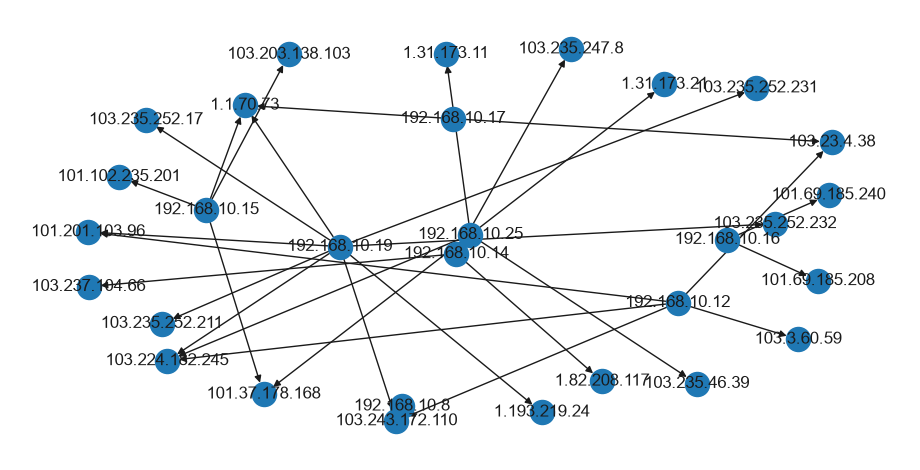

In [64]:
# Визуализация «ядра» графа: подграф на 30 самых центральных узлах
top_nodes = central.head(30).index.tolist()
H = G.subgraph(top_nodes)
pos = nx.spring_layout(H, seed=42)
nx.draw(H, pos, with_labels=True)

print("Рисунок показывает только 30 наиболее центральных узлов; остальные связи сохранены в полном G.")